
# Correlaciones en el mar
El análisis de correlación, a pesar de su simplicidad y de sus múltiples limitaciones, sigue siendo una pieza central del análisis empírico en muchos campos, en particular en las paleociencias. Calcular correlaciones es lo bastante trivial; la dificultad radica en evaluar correctamente su significancia. Son especialmente importantes cuatro consideraciones:

1. __Persistence__, que viola el supuesto estándar de independencia de los datos (sobre el cual se basa la prueba clásica de significancia implementada).
1. __Time irregularities__, como la comparación de dos registros con diferentes ejes temporales, posiblemente con intervalos desiguales (lo que el software estándar no puede manejar directamente).
1. __Age uncertainties__, por ejemplo al comparar dos registros, cada uno con un conjunto de cronologías plausibles (generadas, por ejemplo, mediante un modelo de edades bayesiano).
1. __Test multiplicity__ también conocido como el “efecto de buscar en otra parte” (Look Elsewhere effect), que indica que realizar repetidamente la misma prueba puede producir tasas inaceptablemente altas de error tipo I (aceptar correlaciones como significativas cuando en realidad no lo son). Esto surge, por ejemplo, al correlacionar un registro paleoclimático con un campo instrumental, evaluando la significancia en miles de puntos de grilla a la vez, o al evaluar la significancia dentro de un conjunto de cronologías.

En este notebook reproducimos el estudio de [McCabe-Glynn et al. (2013)](https://www.nature.com/articles/ngeo1862), particularmente el ejemplo de su sección 4, que ilustra varias de estas trampas a la vez. Este ejemplo ilustra el problema de confiar demasiado en correlaciones entre un registro paleoclimático y un campo instrumental para interpretar dicho registro.

Antes de comenzar, una advertencia: los estudios analizados en este trabajo no son casos aislados. Simplemente resultaron ser casos que conocíamos y que consideramos merecían una segunda revisión a la luz de estadísticas más rigurosas. El mismo estudio podría haberse escrito sustituyendo cualquier cantidad de otros registros interpretados, total o parcialmente, sobre la base de correlaciones. En consecuencia, lo que sigue no debe entenderse como una acusación hacia un estudio particular o un grupo de autores, sino más bien como una muestra de lo fácil que resulta, incluso para los científicos mejor intencionados, dejarse engañar por correlaciones espurias.

En este sentido, Pyleoclim facilita una evaluación de correlaciones que aborda todos estos casos, hace transparentes para el usuario las transformaciones de datos necesarias y permite generar gráficos de resultados con comandos de una sola línea. 

## Data Exploration
 We start by loading a few useful packages:

In [1]:
pip install h5netcdf

Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install xarray

Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install netCDF4

Note: you may need to restart the kernel to use updated packages.


In [4]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import warnings
warnings.filterwarnings('ignore')
import pyleoclim as pyleo
from pylipd import LiPD
pyleo.set_style('web')  # set the visual style

Podemos utilizar el paquete PyliPD para abrir el archivo y seleccionar la serie temporal apropiada 

In [5]:
D = D = LiPD()
D.load('./data/Crystal.McCabe-Glynn.2013.lpd')

df = D.get_timeseries_essentials()
df.head()

Loading 1 LiPD files


100%|█████████████████████████████████████████████| 1/1 [00:00<00:00,  2.19it/s]


Loaded..


,dataSetName,archiveType,geo_meanLat,geo_meanLon,geo_meanElev,paleoData_variableName,paleoData_values,paleoData_units,paleoData_proxy,paleoData_proxyGeneral,time_variableName,time_values,time_units,depth_variableName,depth_values,depth_units
0,Crystal.McCabe-Glynn.2013,speleothem,36.59,-118.82,1386.0,d18o,"[-8.01, -8.23, -8.61, -8.54, -8.6, -9.08, -8.9...",permil VPDB,None,None,age,"[2007.7, 2007.0, 2006.3, 2005.6, 2004.9, 2004....",AD,depth,"[0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0...",mm


Let's create a [`GeoSeries` object](https://pyleoclim-util.readthedocs.io/en/latest/core/api.html#pyleoclim.core.geoseries.GeoSeries): 

In [6]:
cc = pyleo.GeoSeries(time=df['time_values'][0], value = df['paleoData_values'][0], lat = df['geo_meanLat'][0],
                     lon = df['geo_meanLon'][0], elevation = df['geo_meanElev'][0], time_name= 'Age', time_unit = df['time_units'][0],
                     value_name = '$\delta^{18}O$', value_unit = u'\u2030', label = df['dataSetName'][0], 
                     archiveType = df['archiveType'][0], depth = df['depth_values'][0], 
                     depth_name = df['depth_variableName'][0], depth_unit = df['depth_units'],verbose = False)

Hagamos un gráfico rápido para comprobar que tenemos lo que queremos.

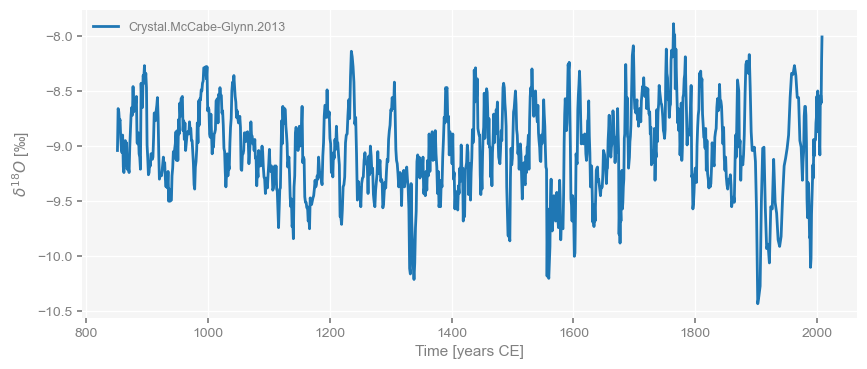

In [7]:
fig, ax = cc.plot()

Creemos un panel [dashboard](https://pyleoclim-util.readthedocs.io/en/latest/core/api.html#pyleoclim.core.geoseries.GeoSeries.dashboard), que ofrezca una vista general de la serie temporal, la ubicación del registro y los picos espectrales.

Performing spectral analysis on individual series: 100%|█| 200/200 [00:34<00:00,


(<Figure size 1100x800 with 4 Axes>,
 {'ts': <Axes: xlabel='Time [years CE]', ylabel='$\\delta^{18}O$ [‰]'>,
  'dts': <Axes: xlabel='Counts'>,
  'map': {'map': <GeoAxes: xlabel='lon', ylabel='lat'>},
  'spec': <Axes: xlabel='Period [years]', ylabel='PSD'>})

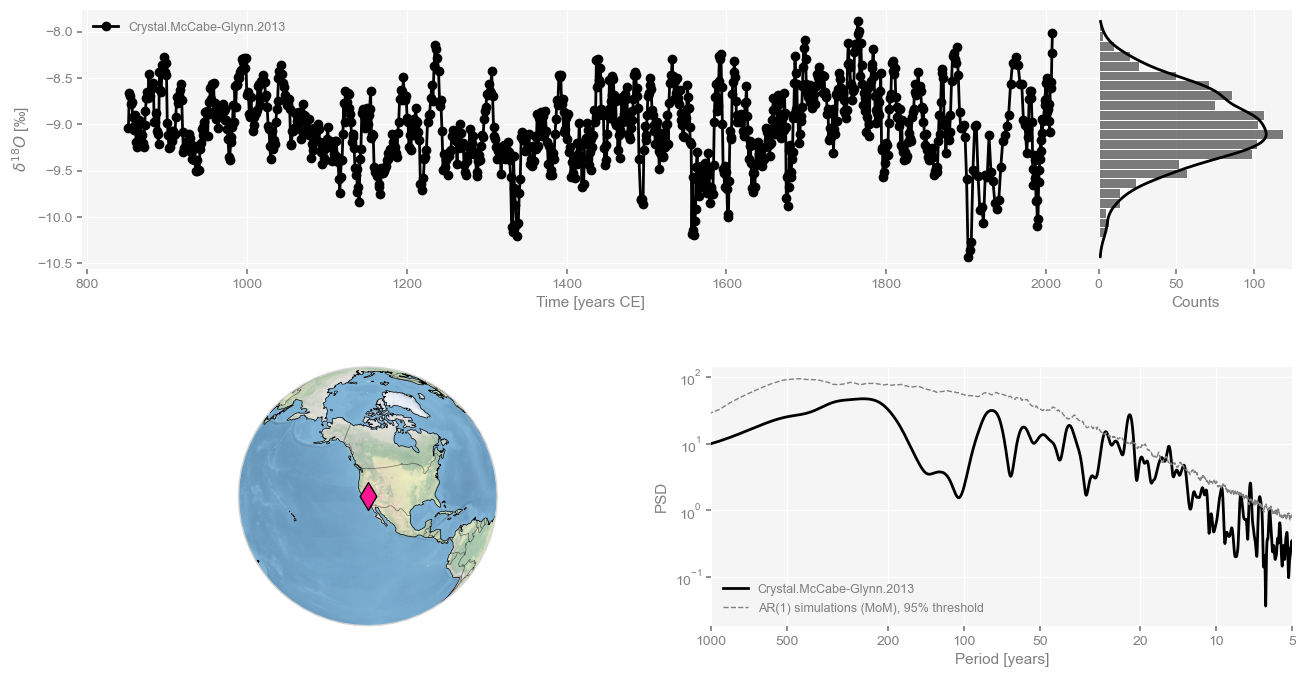

In [8]:
cc.dashboard()

Este es un registro de muy alta resolución, con un espaciado cercano al anual (revísalo), y un espectro ampliamente rojo que exhibe varios picos espectrales en escalas interanuales y decadales.

### Temperatura superficial del mar (SST)

El artículo original correló el registro anterior con el conjunto de datos Kaplan SST. En este cuaderno, en cambio, utilizamos el conjunto de datos HadSST4 (Morice et al., 2012), que está más actualizado y que primero descargamos vía wget (~8 Mb).

A continuación lo cargamos mediante el excelente paquete xarray.

In [10]:
ds = xr.open_dataset('./data/HadSST.4.0.1.0_median.nc')
print(ds)

<xarray.Dataset> Size: 22MB
Dimensions:         (time: 2093, latitude: 36, longitude: 72, bnds: 2)
Coordinates:
  * time            (time) datetime64[ns] 17kB 1850-01-16T12:00:00 ... 2024-0...
  * latitude        (latitude) float64 288B -87.5 -82.5 -77.5 ... 77.5 82.5 87.5
  * longitude       (longitude) float64 576B -177.5 -172.5 ... 172.5 177.5
Dimensions without coordinates: bnds
Data variables:
    tos             (time, latitude, longitude) float32 22MB ...
    time_bnds       (time, bnds) datetime64[ns] 33kB ...
    latitude_bnds   (latitude, bnds) float64 576B ...
    longitude_bnds  (longitude, bnds) float64 1kB ...
Attributes:
    comment:      
    history:      Converted to netcdf today
    institution:  Met Office
    reference:    Kennedy et al. (2019), https://www.metoffice.gov.uk/hadobs/...
    source:       surface observation
    title:        Ensemble-median sea-surface temperature anomalies from the ...
    version:      HadSST.4.0.1.0
    Conventions:  CF-1.7


Como ejemplo, consideremos únicamente el Océano Pacífico del Hemisferio Norte. Por practicidad, ajustemos primero el sistema de coordenadas de modo que la longitud se exprese de 0 a 360 grados en lugar de 180O a 180E.

In [11]:
ds_rolled = ds.assign_coords(longitude=(ds.longitude % 360)).sortby(ds.longitude)
ds_rolled

<xarray.Dataset> Size: 22MB
Dimensions:         (time: 2093, latitude: 36, longitude: 72, bnds: 2)
Coordinates:
  * time            (time) datetime64[ns] 17kB 1850-01-16T12:00:00 ... 2024-0...
  * latitude        (latitude) float64 288B -87.5 -82.5 -77.5 ... 77.5 82.5 87.5
  * longitude       (longitude) float64 576B 2.5 7.5 12.5 ... 347.5 352.5 357.5
Dimensions without coordinates: bnds
Data variables:
    tos             (time, latitude, longitude) float32 22MB ...
    time_bnds       (time, bnds) datetime64[ns] 33kB ...
    latitude_bnds   (latitude, bnds) float64 576B ...
    longitude_bnds  (longitude, bnds) float64 1kB ...
Attributes:
    comment:      
    history:      Converted to netcdf today
    institution:  Met Office
    reference:    Kennedy et al. (2019), https://www.metoffice.gov.uk/hadobs/...
    source:       surface observation
    title:        Ensemble-median sea-surface temperature anomalies from the ...
    version:      HadSST.4.0.1.0
    Conventions:  CF-1.7

Ahora seleccionemos los datos necesarios:

In [12]:
ds_sel = ds_rolled.sel(longitude=slice(120,280),latitude=slice(0,90))
ds_sel

<xarray.Dataset> Size: 5MB
Dimensions:         (time: 2093, latitude: 18, longitude: 32, bnds: 2)
Coordinates:
  * time            (time) datetime64[ns] 17kB 1850-01-16T12:00:00 ... 2024-0...
  * latitude        (latitude) float64 144B 2.5 7.5 12.5 17.5 ... 77.5 82.5 87.5
  * longitude       (longitude) float64 256B 122.5 127.5 132.5 ... 272.5 277.5
Dimensions without coordinates: bnds
Data variables:
    tos             (time, latitude, longitude) float32 5MB ...
    time_bnds       (time, bnds) datetime64[ns] 33kB ...
    latitude_bnds   (latitude, bnds) float64 288B ...
    longitude_bnds  (longitude, bnds) float64 512B ...
Attributes:
    comment:      
    history:      Converted to netcdf today
    institution:  Met Office
    reference:    Kennedy et al. (2019), https://www.metoffice.gov.uk/hadobs/...
    source:       surface observation
    title:        Ensemble-median sea-surface temperature anomalies from the ...
    version:      HadSST.4.0.1.0
    Conventions:  CF-1.7

## Trampa #1: Persistence

Persistencia es la tendencia de muchas series temporales geofísicas (particularmente en paleoclimatología) a mostrar algún tipo de memoria: las observaciones consecutivas tienden a parecerse entre sí, lo que da lugar a series que presentan tendencias relativamente amplias y fluctuaciones de baja frecuencia, y comparativamente pocas fluctuaciones de alta frecuencia. Esto tiene una consecuencia importante: el supuesto estándar de independencia, que sustenta gran parte de la estadística frecuentista, se ve violado en este caso. En una serie temporal con observaciones totalmente independientes (por ejemplo, ruido blanco), los grados de libertad para la varianza son máximos. Pero si existe memoria, este número puede reducirse drásticamente.

Veamos un punto aleatorio y construyamos algo de intuición. Primero, necesitamos calcular anomalías mensuales y anualizarlas. xarray lo facilita (cuatro líneas de código más otra línea para graficar), así que observemos el resultado:

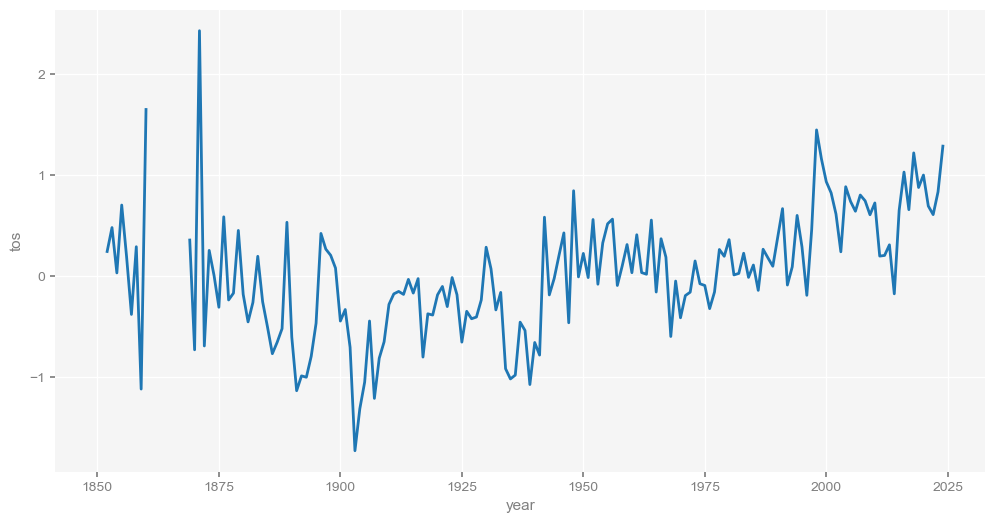

In [13]:
st = ds['tos'].sel(latitude=32.5, longitude = 142.5, method='nearest')  # 32.5N 142.5W near Kuroshio Extension
climatology = st.groupby("time.month").mean("time")
anomalies = st.groupby("time.month") - climatology
st_annual = anomalies.groupby("time.year").mean("time")
st_annual.plot(figsize=[12, 6])

Observa los vacíos de cobertura en la década de 1860. Esto, junto con el hecho de que la cronología de Crystal Cave no está uniformemente espaciada, normalmente haría difícil comparar ambas series, requiriendo algún tipo de interpolación o agrupamiento (binning). Pyleoclim se encarga de todo esto de manera interna, siempre que los datos de temperatura se conviertan en un objeto Series, lo cual es una operación rápida:

In [14]:
stts = pyleo.Series(time=st_annual.coords['year'].values,
                    time_unit ='year CE', 
                    value=st_annual.values, value_name='SST',
                    value_unit = 'C', label='HadCRUT4, 32.5N, 142.5E')

NaNs have been detected and dropped.
Time axis values sorted in ascending order


Now we can compute correlations with the Crystal Cave record. 

In [15]:
corr_res = stts.correlation(cc, seed = 2333)
print(corr_res.r)

Evaluating association on surrogate pairs: 100%|█| 1000/1000 [00:00<00:00, 1265.

0.3235963792817965


Pasaron varias cosas aquí. Primero, pyleoclim fue lo suficientemente inteligente como para identificar un intervalo temporal común entre los dos registros y utilizó interpolación lineal para alinear ambas series temporales en un mismo eje. La mayoría de los usuarios agradecerá no tener que hacer esto explícitamente, aunque el proceso puede personalizarse (see [Timeseries alignment](#alignment)). 

La correlación es $r=0.324$, y la pregunta natural es: “¿Es este valor significativo (es decir, inusual)?” La forma estándar de evaluarlo es mediante una prueba t, usando el estadístico de prueba: $$T = \frac{r \sqrt{n-2}}{\sqrt{1-r^2}}$$ (see e.g. Wilks, 2011) Si sustituimos los valores de $r$ and $n$, obtenemos:

In [16]:
ccs = cc.slice([1854,2020])
n = len(ccs.time)
nu = n-2
r = corr_res.r
T  = r *np.sqrt(nu)/(np.sqrt(1-r**2))
print("The test statistic is "+ str(T))

The test statistic is 3.586899835725328


Bajo los supuestos estándar (los datos son independientes e idénticamente distribuidos), $T$ follows Student's $t$ distribution. sigue una distribución t de Student. Si hacemos la misma suposición y usamos la distribución t de SciPy, podemos calcular fácilmente el valor p (es decir, la probabilidad de observar un estadístico de prueba al menos tan grande como este, bajo la distribución nula):

In [17]:
from scipy.stats import t
pval = 1-t.cdf(T,nu)
print("The p-value is {:10.2e}".format(pval)) # express in exponential notation

The p-value is   2.50e-04


En otras palabras, utilizando la prueba clásica de significancia de correlaciones “tal cual”, se concluiría que la SST en 42°N, 164°E comparte tanta similitud con el registro de Crystal Cave que existirían unas 2 posibilidades en 10.000 de que esto ocurriera al azar. En otras palabras, parece bastante significativo.

Sin embargo, esta prueba (que es la que implementan por defecto la mayoría de los paquetes computacionales, incluido Excel) no es apropiada en este caso, ya que la teoría solo aplica a datos que son independientes e idénticamente distribuidos (IID). Independencia significa que las observaciones consecutivas no tienen poder predictivo entre sí, lo cual no es cierto ni para Crystal Cave ni para el objetivo instrumental. Es decir: como la temperatura de un año tiende a parecerse a la del año anterior o al siguiente (lo mismo ocurre con el δ18O), los datos distan mucho de ser independientes. Más adelante cuantificaremos esta dependencia y sus consecuencias.

El resultado completo del comando correlation() de Pyleoclim se ve así:

In [18]:
print(corr_res)

  correlation    p-value  signif. (α: 0.05)
-------------  ---------  -------------------
     0.323596       0.14  False



Es decir, el valor de la correlación viene acompañado de una estimación del valor p y de una bandera booleana (True/False) que indica si este se encuentra o no por debajo del nivel de prueba α. Sin embargo, aquí el valor p se estima en 14% $\alpha$, y por lo tanto la correlación no se considera significativa (`'signif': False`) a 5% level (`'alpha': 0.05`). How did `pyleoclim` arrive at such a different conclusion than the $2.5 \times 10^{-4}$ seen just above? 

Modelos nulos

De hecho, en Pyleoclim existen 3 maneras de hacer esta determinación. Mientras que el modelo nulo estándar para correlaciones en la literatura estadística es el modelo IID, acabamos de ver que este se ve violado por la persistencia de muchas series temporales, en particular las mostradas arriba. El paquete implementa la clásica prueba t, pero ajustada por la pérdida de grados de libertad debida a la persistencia, tal como se describe en Dawdy & Matalas (1964):

In [19]:
corr_ttest = stts.correlation(cc,statistic='pearsonr',method='ttest')
print(corr_ttest)

  correlation    p-value  signif. (α: 0.05)
-------------  ---------  -------------------
     0.323596       0.16  False



As a result, the the p-value for the test is now 16%, far above the  $2.4 \times 10^{-4}$ it would be under the IID assumption. 

La siguiente opción compara la correlación observada con la distribución de correlaciones obtenidas a partir de (por defecto) 1000 series temporales autorregresivas generadas aleatoriamente (AR(1)), con los mismos parámetros de persistencia que la serie original, medidos mediante la autocorrelación en el rezago 1. Este modelo es paramétrico y preserva las propiedades de persistencia de cada serie:

In [20]:
corr_isopersist = stts.correlation(cc,statistic='pearsonr',method='ar1sim', seed = 2333)
print(corr_isopersist)

Evaluating association on surrogate pairs: 100%|█| 1000/1000 [00:00<00:00, 1235.

  correlation    p-value  signif. (α: 0.05)
-------------  ---------  -------------------
     0.323596       0.11  False



Como este es un método basado en simulaciones, el resultado dependerá del número de simulaciones, nsim. Aumentar nsim garantiza resultados más consistentes, aunque en este caso el resultado no cambia:

In [21]:
corr_isopersist = stts.correlation(cc,statistic='pearsonr',method='ar1sim', seed = 2333, number = 2000)
print(corr_isopersist)

Evaluating association on surrogate pairs: 100%|█| 2000/2000 [00:01<00:00, 1208.

  correlation    p-value  signif. (α: 0.05)
-------------  ---------  -------------------
     0.323596       0.12  False



Vemos que el valor p cambia sutilmente entre estos dos casos, pero no lo suficiente como para modificar el resultado (la correlación no es significativa en ninguno de los dos). Sin embargo, para asegurar que estos problemas de muestreo no afecten la reproducibilidad de los resultados, especificamos una semilla aleatoria. Cabe señalar que la diferencia entre valores p “significativos” y “no significativos” no es en sí misma estadísticamente significativa (Gelman & Stern, 2006).

El último método de modelo nulo es phaseran, que aleatoriza las fases de las señales originales, preservando así el espectro de cada serie pero desordenando las relaciones de fase entre las señales. Este método (no paramétrico) fue propuesto por primera vez por Ebisuzaki (1997), y se denomina phaseran porque mantiene intacto el espectro (y, por lo tanto, la función de autocorrelación). Dado que también se trata de un método de simulación, se puede ajustar el número de simulaciones, como se hace aquí:

In [22]:
corr_isospec = stts.correlation(cc,statistic='pearsonr',method='phaseran', seed = 4343, number = 2000)
print(corr_isospec)

Evaluating association on surrogate pairs: 100%|█| 2000/2000 [00:01<00:00, 1285.

  correlation    p-value  signif. (α: 0.05)
-------------  ---------  -------------------
     0.323596       0.14  False



Vemos que esto dio como resultado un p-valor ligeramente diferente, pero de nuevo superior al 5%, lo que lleva a rechazar la hipótesis nula. En este caso, los tres métodos coinciden en que la correlación es insignificante; sin embargo, animamos a los usuarios a experimentar con estos métodos en caso de obtener resultados cercanos al nivel de significancia, para desincentivar las tentaciones de buscar un p-valor a conveniencia (p-hacking).

### Alineación de series temporales

Como se mencionó anteriormente, las series de SST y de Crystal Cave están en diferentes ejes temporales, y Pyleoclim automatizó el proceso de alinearlas, haciéndolo en segundo plano para que los usuarios puedan concentrarse en hacer ciencia. Sin embargo, es útil comprender qué está sucediendo y cómo se puede personalizar, en caso de que esto marque una diferencia en el análisis. Al igual que otros métodos de Pyleoclim diseñados para comparar series temporales, correlation() se apoya en el método MultipleSeries.common_time() para la alineación. Este método implementa tres estrategias para la alineación de series temporales:

1. interpolation
1. agrupamiento "binning"
1. suavizado por kernel gaussiano

Para explorarlo, primero creemos un objeto MultipleSeries que reúna esas dos series:

(<Figure size 640x480 with 3 Axes>,
 {0: <Axes: ylabel='$\\delta^{18}O$ [‰]'>,
  1: <Axes: ylabel='SST [C]'>,
  'x_axis': <Axes: xlabel='Time [year CE]'>})

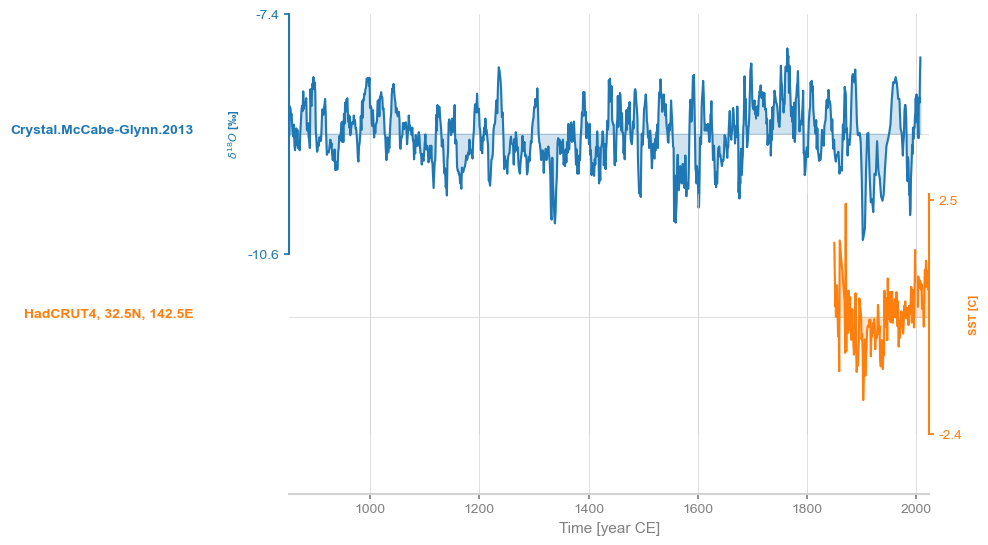

In [23]:
ms = pyleo.MultipleSeries([cc,stts])
ms.stackplot()

Por defecto, common_time() implementará una interpolación lineal.

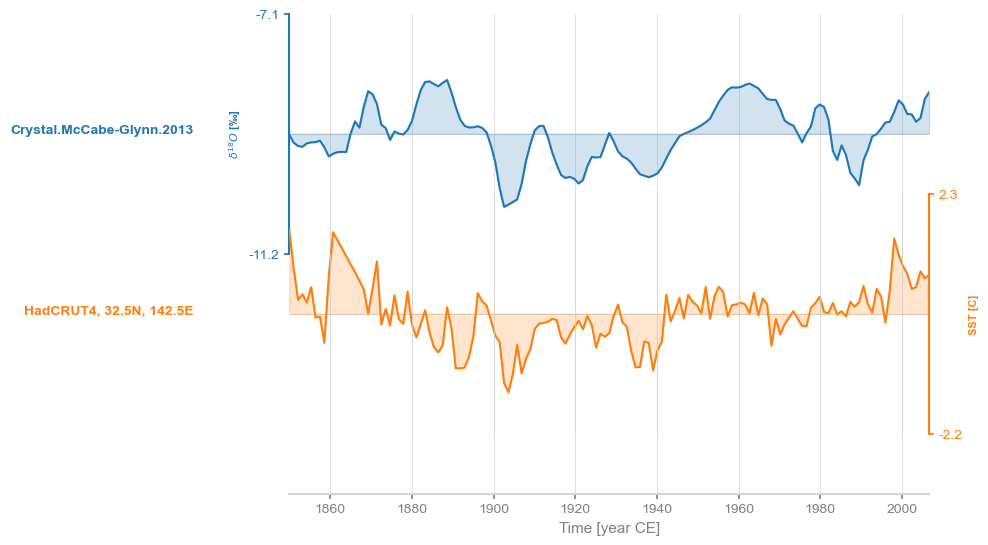

In [24]:
msi = ms.common_time()
fig, ax = msi.stackplot()

Es fácil verificar que las dos series están, de hecho, en el mismo eje:

In [25]:
msi.series_list[0].time == msi.series_list[1].time

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,

Para ver cómo la interpolación cambió la serie original, podemos superponer la serie original como puntos sobre este gráfico de áreas apiladas (stackplot):

<Axes: ylabel='SST [C]'>

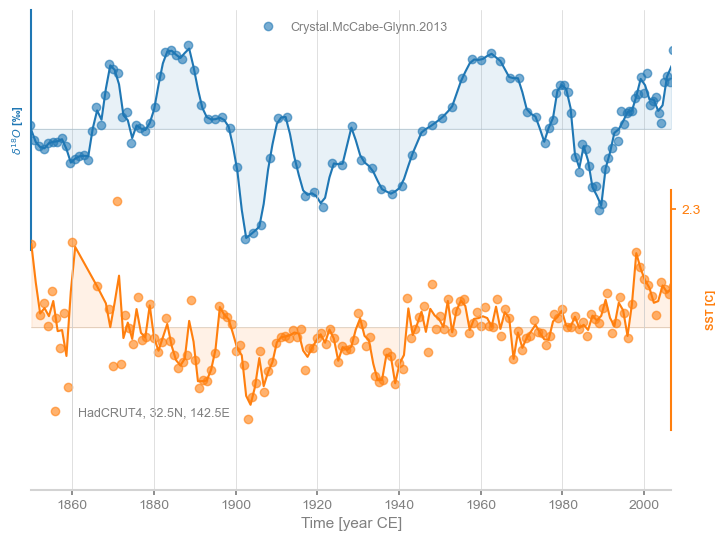

In [26]:
fig, ax = msi.stackplot(labels=None, fill_between_alpha=0.1)
cc.plot(ax=ax[0],marker='o',linestyle='',xlabel='',alpha=0.6)
stts.plot(ax=ax[1],marker='o',linestyle='',color='C1',xlabel='', alpha=0.6)

Vemos que la interpolación dejó el registro de Crystal Cave relativamente inalterado, excepto cerca del final, donde la resolución es muy alta. Para los datos de HadCRUT4, el efecto es más notable en la década de 1870, donde hay una brecha en la cobertura de datos. Esto se puede personalizar: tanto el tipo de interpolación (por ejemplo, lineal, cuadrática) como el paso de la cuadrícula son personalizables (ver la documentación see the [documentation](https://pyleoclim-util.readthedocs.io/en/latest/utils/introduction.html#pyleoclim.utils.tsutils.interp). 

Como ejemplo, podríamos usar la interpolación por spline cúbico, que conlleva el conocido riesgo de sobreajuste (overfitting), creando así excursiones poco realistas que se alejan de las observaciones (


<Axes: ylabel='SST [C]'>

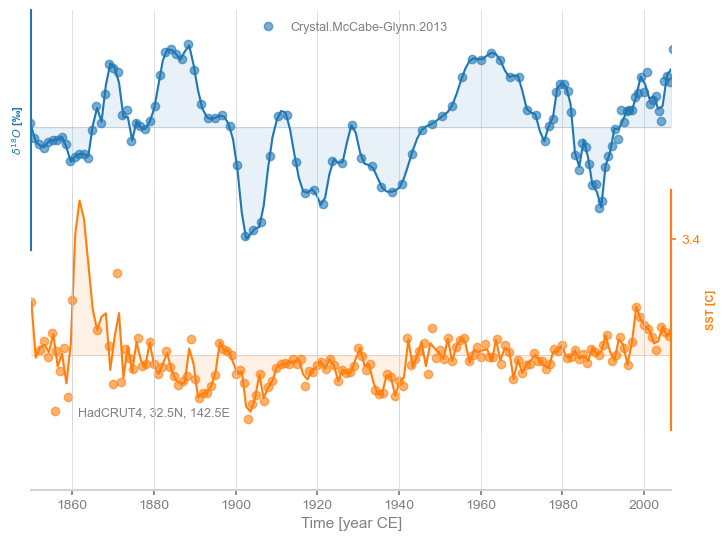

In [27]:
msi = ms.common_time(method='interp',interp_type = 'cubic')
fig, ax = msi.stackplot(labels=None, fill_between_alpha=0.1)
cc.plot(ax=ax[0],marker='o',linestyle='',xlabel='',alpha=0.6)
stts.plot(ax=ax[1],marker='o',linestyle='',color='C1',xlabel='', alpha=0.6)

Otra opción es el agrupamiento (binning), que tiende a suavizar más el grano (coarse-grain), ya que utilizará por defecto el mayor espaciado de tiempo observado en cualquiera de las series para evitar intervalos vacíos.[binning](https://pyleoclim-util.readthedocs.io/en/latest/utils/introduction.html#pyleoclim.utils.tsutils.bin)

<Axes: ylabel='SST [C]'>

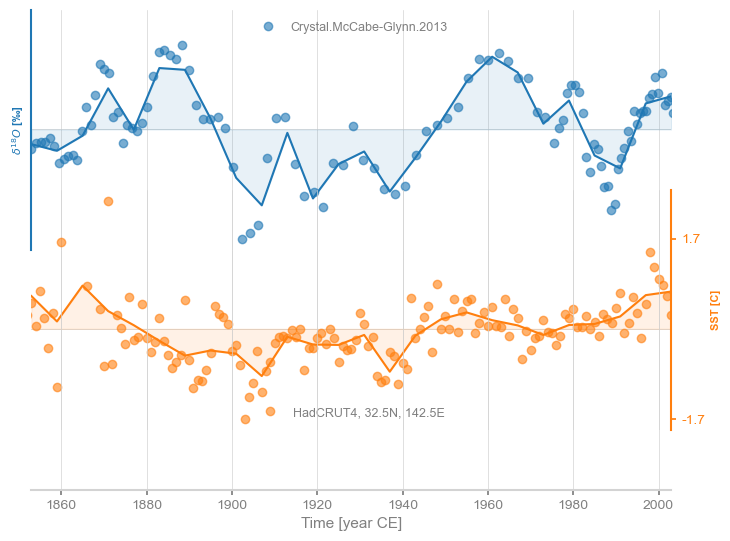

In [28]:
msb = ms.common_time(method='bin')
fig, ax = msb.stackplot(labels=None, fill_between_alpha=0.1)
cc.plot(ax=ax[0],marker='o',linestyle='',xlabel='',alpha=0.6)
stts.plot(ax=ax[1],marker='o',linestyle='',color='C1',xlabel='', alpha=0.6)

Por último, se puede solicitar un kernel gaussiano (Rehfeld & Kurths, 2014), que por defecto utiliza un ancho de banda de 3:

<Axes: ylabel='SST [C]'>

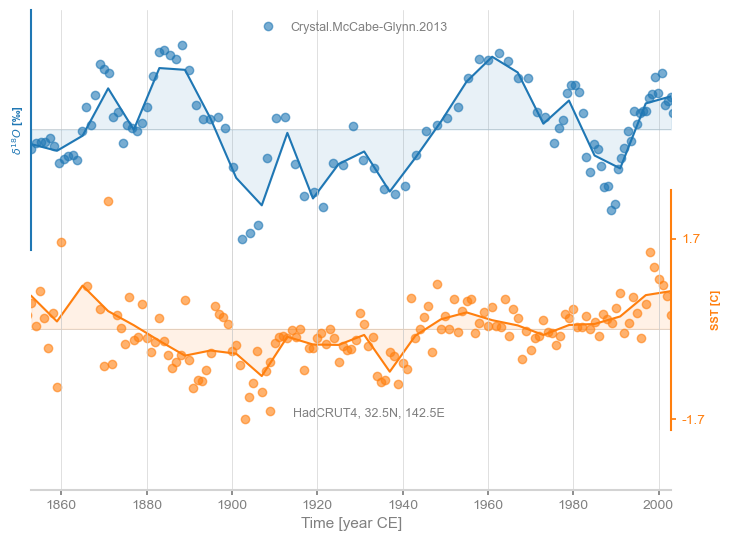

In [29]:
msg = ms.common_time(method='gkernel')
fig, ax = msg.stackplot(labels=None, fill_between_alpha=0.1)
cc.plot(ax=ax[0],marker='o',linestyle='',xlabel='',alpha=0.6)
stts.plot(ax=ax[1],marker='o',linestyle='',color='C1',xlabel='', alpha=0.6)

Es fácil cambiar el ancho de banda $h$:

<Axes: ylabel='SST [C]'>

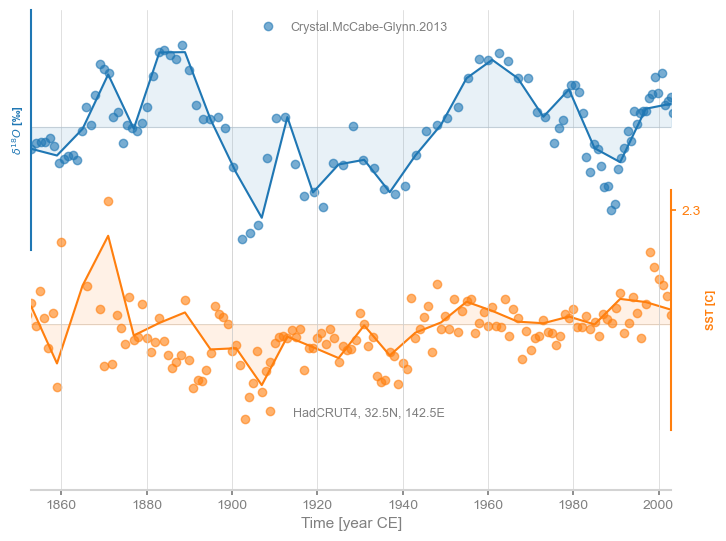

In [29]:
msg = ms.common_time(method='gkernel', h = 0.5)
fig, ax = msg.stackplot(labels=None, fill_between_alpha=0.1)
cc.plot(ax=ax[0],marker='o',linestyle='',xlabel='',alpha=0.6)
stts.plot(ax=ax[1],marker='o',linestyle='',color='C1',xlabel='', alpha=0.6)

El método del kernel gaussiano es bastante conservador y, por lo general, utiliza la resolución más tosca posible. A nivel de correlaciones, los usuarios pueden especificar cómo desean realizar esta alineación temporal mediante el diccionario common_time_kwargs, de la siguiente manera:

In [30]:
corr_isospec = stts.correlation(cc,statistic='pearsonr',method='phaseran', number = 2000, 
                                common_time_kwargs = {'method':'interp','interp_type':'cubic'}, seed = 4343)
print(corr_isospec)

Evaluating association on surrogate pairs: 100%|█| 2000/2000 [00:01<00:00, 1260.

  correlation    p-value  signif. (α: 0.05)
-------------  ---------  -------------------
     0.187768       0.36  False



Vemos que el tipo de interpolación tuvo cierta importancia aquí, reduciendo bastante la correlación original, pero esto no cambia el resultado. Si resulta que esta tarea de bajo nivel afecta al análisis, es prudente echar un vistazo "bajo el capó" ("under the hood") como hicimos aquí, y visualizar cómo la alineación de las series temporales afecta a las series originales. En la mayoría de los casos, sin embargo, esto no debería afectar mucho al resultado final.

Nota: en el caso de la prueba T, sería suficiente poner las series temporales en el mismo eje temporal, pero este eje no necesita estar espaciado uniformemente. Esto no está implementado aquí.

## Trampa #2: Múltiples pruebas de hipótesis

La sección anterior muestra cómo evaluar adecuadamente la significancia en una sola ubicación. La situación se vuelve más compleja cuando se realiza una prueba similar para un campo completo. Para ver por qué, llevemos a cabo la misma prueba de manera recursiva como se hizo anteriormente en todos los puntos de la cuadrícula. Para ello, no solo necesitamos iterar sobre los puntos de la cuadrícula, sino también almacenar los valores p para un análisis posterior. Para ahorrar tiempo, utilizaremos la opción ttest para correlation(), sabiendo que es bastante aproximada. Además, necesitamos excluir los puntos que tienen muy pocas observaciones. El bucle a continuación logra esto.

In [31]:
nlon = len(ds_sel['longitude'])
nlat = len(ds_sel['latitude']) 
pval = np.empty((nlon,nlat)) # declare array to store pvalues
corr = np.empty_like(pval) # declare empty array of identical shape
alpha = 0.05
slon, slat = [], [];
for ji in range(nlon):
    print("Computing correlations at " + str(ds_sel.longitude[ji].values) + 'E')
    for jj in range(nlat):   
        st = ds_sel['tos'][:,jj,ji]
        climatology = st.groupby("time.month").mean("time")
        anomalies = st.groupby("time.month") - climatology
        st_annual = anomalies.groupby("time.year").mean("time")
        #  test if at least 100 non-NaNs
        noNaNs = len(np.where(np.isnan(st_annual) == False)[0]) # number of valid years
        sstvar = st_annual.var()
        if noNaNs >= 100 and sstvar >= 0.01:
            sttb = pyleo.Series(time=st_annual.coords['year'].values,
                        time_unit ='year CE', 
                        value=st_annual.values,
                        value_unit = 'C', verbose=False)
            corr_res = sttb.correlation(cc, method='ttest')
            pval[ji,jj] = corr_res.p
            corr[ji,jj] = corr_res.r
            if pval[ji,jj] < alpha:
                slon.append(ds_sel.longitude[ji])
                slat.append(ds_sel.latitude[jj])
        else:  
            pval[ji,jj] = np.nan; corr[ji,jj] = np.nan

Computing correlations at 122.5E
Computing correlations at 127.5E
Computing correlations at 132.5E
Computing correlations at 137.5E
Computing correlations at 142.5E
Computing correlations at 147.5E
Computing correlations at 152.5E
Computing correlations at 157.5E
Computing correlations at 162.5E
Computing correlations at 167.5E
Computing correlations at 172.5E
Computing correlations at 177.5E
Computing correlations at 182.5E
Computing correlations at 187.5E
Computing correlations at 192.5E
Computing correlations at 197.5E
Computing correlations at 202.5E
Computing correlations at 207.5E
Computing correlations at 212.5E
Computing correlations at 217.5E
Computing correlations at 222.5E
Computing correlations at 227.5E
Computing correlations at 232.5E
Computing correlations at 237.5E
Computing correlations at 242.5E
Computing correlations at 247.5E
Computing correlations at 252.5E
Computing correlations at 257.5E
Computing correlations at 262.5E
Computing correlations at 267.5E
Computing 

In [32]:
pvals = pval.flatten() # make the p-value array a 1D one
pvec = pvals[pvals<1] # restrict to valid probabilities as there are a few weird values.
nt = len(pvec)
print(str(nt)) # check on the final number

328


Encontramos 328 ubicaciones con datos suficientes para una comparación significativa, y 23 ubicaciones que superan la prueba. ¿Dónde están? Para obtener información, grafiquemos las correlaciones e indiquemos (mediante sombreado) cuáles se consideran significativas:

Text(0.5, 1.0, 'R')

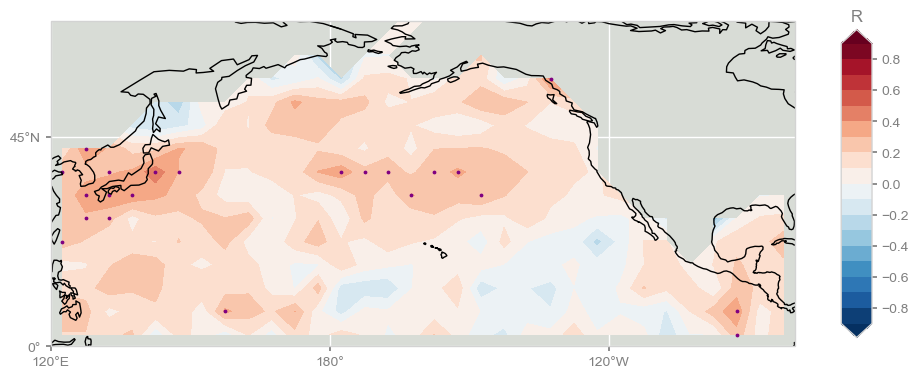

In [33]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import seaborn as sns

land_color=sns.xkcd_rgb['light grey']
ocean_color=sns.xkcd_rgb['light grey']

fig = plt.figure(figsize=[12, 8])
ax = plt.subplot(projection=ccrs.PlateCarree(central_longitude=180))

# map
ax.add_feature(cfeature.LAND, facecolor=land_color, edgecolor=land_color)
ax.add_feature(cfeature.OCEAN, facecolor=ocean_color, edgecolor=ocean_color)
ax.coastlines()

transform = ccrs.PlateCarree()
latlon_range = (120, 280, 0, 70)
lon_min, lon_max, lat_min, lat_max = latlon_range
lon_ticks = [60, 120, 180, 240, 300]
lat_ticks = [-90, -45, 0, 45, 90]

ax.set_extent(latlon_range, crs=transform)
lon_formatter = LongitudeFormatter(zero_direction_label=False)
lat_formatter = LatitudeFormatter()
ax.xaxis.set_major_formatter(lon_formatter)
ax.yaxis.set_major_formatter(lat_formatter)
lon_ticks = np.array(lon_ticks)
lat_ticks = np.array(lat_ticks)
mask_lon = (lon_ticks >= lon_min) & (lon_ticks <= lon_max)
mask_lat = (lat_ticks >= lat_min) & (lat_ticks <= lat_max)
ax.set_xticks(lon_ticks[mask_lon], crs=transform)
ax.set_yticks(lat_ticks[mask_lat], crs=transform)

# contour
clevs = np.linspace(-0.9, 0.9, 19)
#corr_r, lon_r = rotate_lon(corr.T, lon)  # rotate the field to make longitude in increasing order and convert to range (0, 360)
im = ax.contourf(ds_sel.longitude, ds_sel.latitude, corr.T, clevs, transform=transform, cmap='RdBu_r', extend='both')

# significant points
plt.scatter(x=slon, y=slat, color="purple", s=3,
            alpha=1,
            transform=transform) 


# colorbar
cbar_pad = 0.05
cbar_orientation = 'vertical'
cbar_aspect = 10
cbar_fraction = 0.15
cbar_shrink = 0.5
cbar_title = 'R'
cbar = fig.colorbar(im, ax=ax, orientation=cbar_orientation, pad=cbar_pad, aspect=cbar_aspect,
                    fraction=cbar_fraction, shrink=cbar_shrink)
cbar.ax.set_title(cbar_title)

Los puntos púrpuras en el mapa son las ubicaciones de los puntos de la cuadrícula donde los valores p caen por debajo del 5%, y corresponden naturalmente a las regiones de correlaciones más altas, aunque (y esto es sospechoso) están dispersos de manera bastante aleatoria por todo el dominio. Podríamos sentirnos tentados a declarar la victoria y aclamarlos como "significativos", pero este es un problema bien conocido: el problema de las hipótesis múltiples, también conocido como el efecto de "buscar en otra parte" ("look elsewhere effect"). Realizar pruebas al nivel del 5% (lo que la mayoría de la gente llamaría "el nivel de confianza del 95%") significa específicamente que esperamos que el 5% de nuestras pruebas arrojen resultados espurios, solo por casualidad (el llamado "error de tipo I"). Acabamos de realizar 327 pruebas, por lo que esperamos que $0.05 * 327 \approx 16$ de esos resultados sean falsos positivos, de entrada. Entonces, ¿cuáles de las 23 pruebas etiquetadas como significativas podemos confiar? Una forma de abordar esto es ordenar por rango los valores p de las 327 pruebas y graficarlos como en Hu et al (2017), Fig 2.

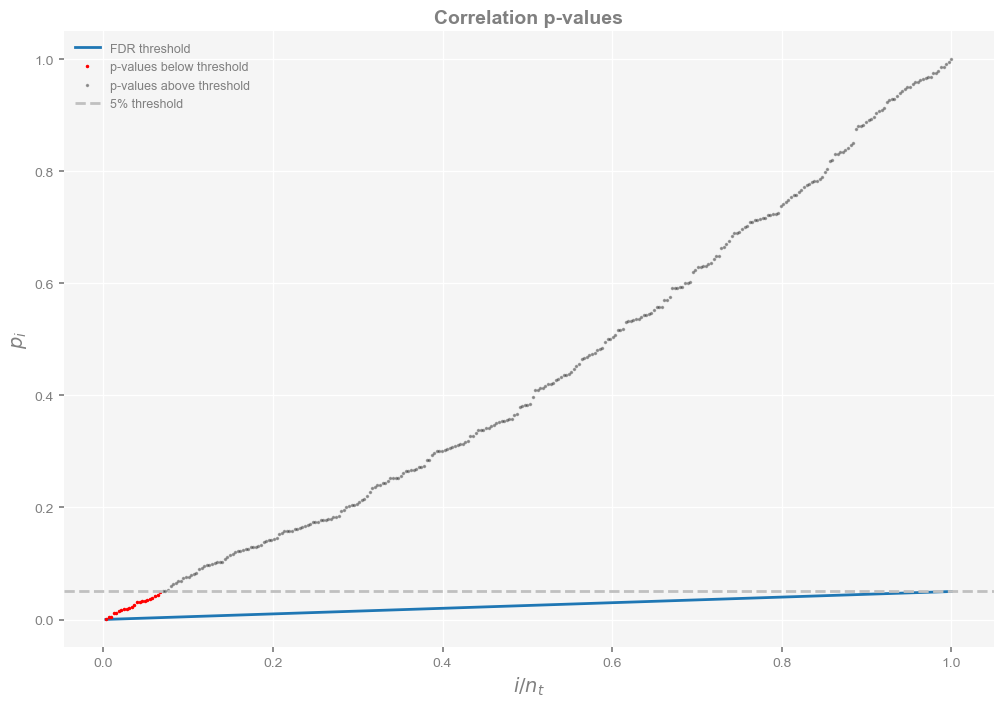

In [34]:
#check i/m vs. p-values
indexm = np.arange(1,nt+1,1)
im = 1.0*indexm / nt
thres = 0.05*im
pvec_s = sorted(pvec)
smaller=[]
small_index=[]
larger=[]
large_index=[]

n=0
for pp in pvec_s:
    if pp <=0.05:
        smaller.append(pp)
        small_index.append(im[n])
    else:
        larger.append(pp)
        large_index.append(im[n])
    n=n+1

f, ax = plt.subplots(figsize=(12,8))
plt.plot(im,thres,label='FDR threshold')
plt.plot(small_index,smaller,'ro',markersize=1.5,label='p-values below threshold')
plt.plot(large_index,larger,'ko',markersize=1.5,label='p-values above threshold',alpha=0.3)
plt.axhline(y=0.05,linestyle='dashed',color='silver',label='5% threshold')
plt.xlabel(r'$i/n_t$',fontsize=14)
plt.ylabel(r'$p_i$',fontsize=14)
plt.title('Correlation p-values',fontsize=14, fontweight='bold')
plt.legend()

Una solución a esto es la Tasa de Falsos Descubrimientos (también conocida como FDR, por sus siglas en inglés), la cual fue ideada en un célebre artículo de 1995 (Benjamini & Hochberg, 1995). La idea es buscar no solo los valores p por debajo del 5% (puntos rojos en la figura anterior), sino la fracción de aquellos que se encuentran por debajo de la línea azul, lo que protege contra los falsos descubrimientos que se esperan al probar repetidamente la misma hipótesis una y otra vez. Para acceder a esta funcionalidad en pyleoclim, se puede hacer lo siguiente:

In [35]:
fdr_res = pyleo.utils.correlation.fdr(pvec_s)
print(fdr_res)

None


Y con este tratamiento, exactamente 0 puntos de la cuadrícula superan la prueba.

¿Esto depende de nuestro método para evaluar la significancia? Eso es fácil de comprobar:

In [37]:
pval2 = np.empty((nlon,nlat)) # declare array to store pvalues
corr2 = np.empty_like(pval) # declare empty array of identical shape
slon, slat = [], [];
sst_list = [] # initialize empty list 

for ji in range(nlon):
    print("Computing correlations at " + str(ds_sel.longitude[ji].values) + 'E')
    for jj in range(nlat):  
        st = ds_sel['tos'][:,jj,ji]
        climatology = st.groupby("time.month").mean("time")
        anomalies = st.groupby("time.month") - climatology
        st_annual = anomalies.groupby("time.year").mean("time")
        #  test if at least 100 non-NaNs
        noNaNs = len(np.where(np.isnan(st_annual) == False)[0]) # number of valid years
        sstvar = st_annual.var()
        if noNaNs >= 100 and sstvar >= 0.01:
            sttb = pyleo.Series(time=st_annual.coords['year'].values,
                        time_unit ='year CE', 
                        value=st_annual.values,
                        value_unit = 'C', verbose=False)
            sst_list.append(sttb) 
            corr_res = sttb.correlation(cc, method='phaseran',number =1000,seed=333, mute_pbar=True)
            pval2[ji,jj] = corr_res.p
            corr2[ji,jj] = corr_res.r
            if pval2[ji,jj] < alpha:
                slon.append(ds_sel.longitude[ji])
                slat.append(ds_sel.latitude[jj])
        else:  
            pval2[ji,jj] = np.nan; corr2[ji,jj] = np.nan

Computing correlations at 122.5E
Computing correlations at 127.5E
Computing correlations at 132.5E
Computing correlations at 137.5E
Computing correlations at 142.5E
Computing correlations at 147.5E
Computing correlations at 152.5E
Computing correlations at 157.5E
Computing correlations at 162.5E
Computing correlations at 167.5E
Computing correlations at 172.5E
Computing correlations at 177.5E
Computing correlations at 182.5E
Computing correlations at 187.5E
Computing correlations at 192.5E
Computing correlations at 197.5E
Computing correlations at 202.5E
Computing correlations at 207.5E
Computing correlations at 212.5E
Computing correlations at 217.5E
Computing correlations at 222.5E
Computing correlations at 227.5E
Computing correlations at 232.5E
Computing correlations at 237.5E
Computing correlations at 242.5E
Computing correlations at 247.5E
Computing correlations at 252.5E
Computing correlations at 257.5E
Computing correlations at 262.5E
Computing correlations at 267.5E
Computing 

In [39]:
pvals2 = pval2.flatten() # make the p-value array a 1D one
pvec2 = pvals2[pvals2<1] # restrict to valid probabilities as there are a few weird values.
fdr_res2 = pyleo.utils.correlation.fdr(sorted(pvec2))
print(fdr_res2)

None


Aquí, 1 punto de la cuadrícula emerge como significativo con este método. Ahora, otra forma en que podríamos haber hecho esto es agrupar todas las series de TSM de cada punto de la cuadrícula como un objeto MultipleSeries, y dejar que la clase CorrEns haga su magia. Esto permite calcular directamente la correlación entre objetos, y aprovechar la clase CorrEns y su método de gráficos:

In [40]:
sstMS = pyleo.MultipleSeries(sst_list)
corr_ens = sstMS.correlation(cc,method='phaseran',number=1000,seed=333,mute_pbar=True)  

Looping over 328 Series in collection


Evaluating association on surrogate pairs: 100%|█| 1000/1000 [00:00<00:00, 1214.
Evaluating association on surrogate pairs: 100%|█| 1000/1000 [00:00<00:00, 1251.
Evaluating association on surrogate pairs: 100%|█| 1000/1000 [00:00<00:00, 1209.
Evaluating association on surrogate pairs: 100%|█| 1000/1000 [00:00<00:00, 1274.
Evaluating association on surrogate pairs: 100%|█| 1000/1000 [00:00<00:00, 1282.
Evaluating association on surrogate pairs: 100%|█| 1000/1000 [00:00<00:00, 1276.
Evaluating association on surrogate pairs: 100%|█| 1000/1000 [00:00<00:00, 1268.
Evaluating association on surrogate pairs: 100%|█| 1000/1000 [00:00<00:00, 1273.
Evaluating association on surrogate pairs: 100%|█| 1000/1000 [00:00<00:00, 1261.
Evaluating association on surrogate pairs: 100%|█| 1000/1000 [00:00<00:00, 1078.
Evaluating association on surrogate pairs: 100%|█| 1000/1000 [00:00<00:00, 1220.
Evaluating association on surrogate pairs: 100%|█| 1000/1000 [00:00<00:00, 1290.
Evaluating association on su

(<Figure size 400x400 with 1 Axes>, <Axes: xlabel='$r$', ylabel='Count'>)

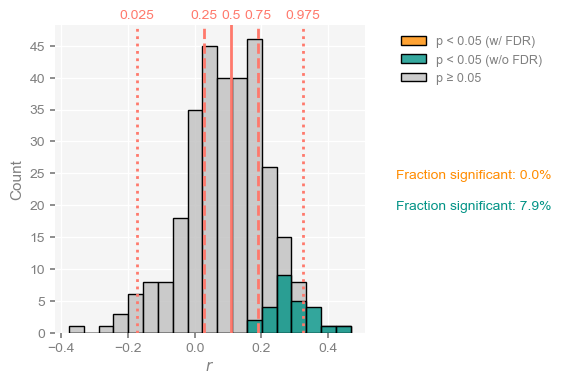

In [41]:
corr_ens.plot()

Para guardar esta figura, hay varias maneras. La manera estándar de matplotlib se vería así:

In [38]:
fig.savefig('CrystalCave_field_corr_hist.pdf')

El formato de archivo se infiere a partir del nombre del archivo, pero es posible que la resolución predeterminada sea demasiado baja para su publicación. Además, el hecho de colocar la leyenda a la derecha ha expandido el cuadro delimitador de la figura (bounding box), pero savefig no sabe esto y recortará el resultado, desperdiciando nuestro esfuerzo. Estos dos problemas se pueden remediar de la siguiente manera:

In [42]:
fig.savefig('CrystalCave_field_corr_hist.pdf', dpi=300, bbox_inches='tight')

Alternatively, users may pass a dictionary called `savefig_settings`:

In [43]:
corr_ens.plot(savefig_settings={'path':'CrystalCave_field_corr_hist.pdf'})

Figure saved at: "CrystalCave_field_corr_hist.pdf"


(<Figure size 400x400 with 1 Axes>, <Axes: xlabel='$r$', ylabel='Count'>)

Por defecto, establece los ppp (dpi) en 300 y bbox_inches='tight', por lo que la ruta es lo único que se necesita especificar. Tenga en cuenta que en este caso el

In [44]:
corr_ens.signif_fdr.count(True)

0

Encontramos el mismo resultado que antes, aunque en una forma mucho más compacta. Tenga en cuenta, sin embargo, que este método no realiza un seguimiento de dónde están los puntos significativos (no tiene noción de lo que significa "dónde"), por lo que si quisiera dibujar un mapa como el anterior, sería mejor utilizar el bucle mostrado anteriormente. 

## Trampa #3: Age uncertainties 

A pesar de las dos primeras trampas, existe una tercera dificultad en esta comparación: por muy bellas que sean las cronologías U/Th, también albergan incertidumbres, y dichas incertidumbres cronológicas deben tenerse en cuenta. El archivo LiPD proporcionado con este notebook contiene no solo las fechas U/Th sin procesar y las edades publicadas, sino también un conjunto de relaciones edad-profundidad derivadas de esas fechas, a través del modelo de edad bayesiano BChron (Haslett & Parnell, 2008). Carguemos esas 1000 extracciones de la distribución a posteriori de las edades y pongámoslas en un objeto donde Pyleoclim pueda trabajar con ellas. Para hacerlo, recurriremos al paquete PyLiPD para manipular el archivo LiPD.

In [45]:
ensemble_df = D.get_ensemble_tables()
ensemble_df.head()

,datasetName,ensembleTable,ensembleVariableName,ensembleVariableValues,ensembleVariableUnits,ensembleDepthName,ensembleDepthValues,ensembleDepthUnits,notes
0,Crystal.McCabe-Glynn.2013,http://linked.earth/lipd/Crystal.McCabe-Glynn....,Year,"[[2007.0, 2007.0, 2008.0, 2007.0, 2007.0, 2007...",AD,depth,"[0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0...",mm,None


In [46]:
cc_ens = pyleo.EnsembleGeoSeries.from_AgeEnsembleArray(geo_series=cc, age_array= ensemble_df.iloc[0]['ensembleVariableValues'],
                                                     age_depth = ensemble_df.iloc[0]['ensembleDepthValues'], 
                                                     value_depth = cc.depth, verbose=False)

El objeto resultante es un EnsembleGeoSeries, un caso especial de MultipleGeoSeries donde todas las series constituyentes tienen las mismas unidades. Hay dos formas de graficar este conjunto. Primero, como una serie de trazas:

<Axes: xlabel='Time [years CE]', ylabel='$\\delta^{18}O$ [‰]'>

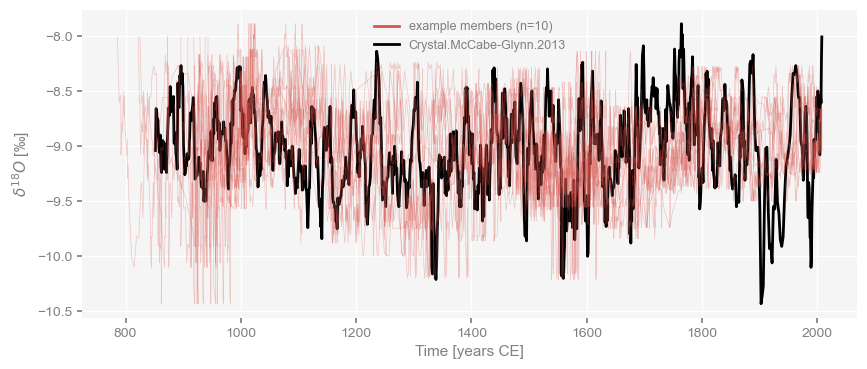

In [47]:
fig, ax = cc_ens.plot_traces()
cc.plot(color='black', ax = ax)

Es bastante evidente que cualquiera de las oscilaciones principales del registro puede desplazarse hacia adelante o hacia atrás hasta por décadas. Otra forma de ver esto es graficar varios cuantiles como una envolvente:

<Axes: xlabel='Time [years CE]', ylabel='$\\delta^{18}O$ [‰]'>

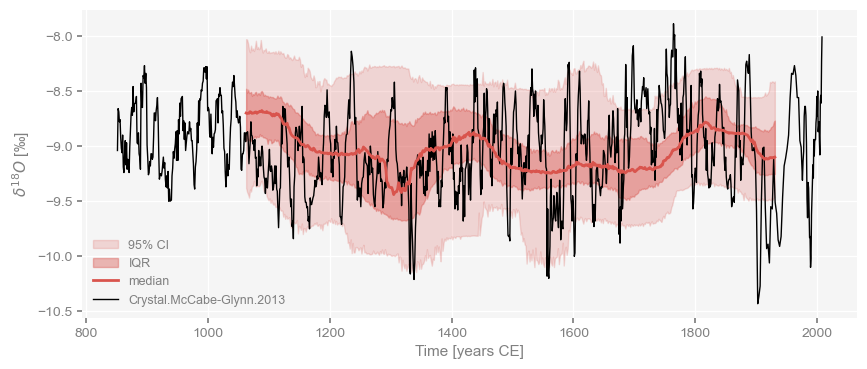

In [48]:
fig, ax = cc_ens.common_time(method='interp').plot_envelope(ylabel = cc.value_name)
cc.plot(color='black', ax = ax, linewidth=1)

Fíjese cómo los cuantiles se calculan solo sobre una parte del intervalo cubierto por la serie original; esto se debe a que algunos modelos de edad terminan estando más comprimidos o estirados que el original, y necesitamos un intervalo común para calcular los cuantiles. En particular, observe cómo la base del registro podría estar en cualquier lugar entre 850 y 1100 d.C.

Performing spectral analysis on individual series: 100%|█| 1000/1000 [00:42<00:0


(<Figure size 1100x800 with 4 Axes>,
 {'ts': <Axes: xlabel='Time [years CE]', ylabel='$\\delta^{18}O$ [‰]'>,
  'dts': <Axes: xlabel='Counts'>,
  'map': {'map': <GeoAxes: xlabel='lon', ylabel='lat'>},
  'spec': <Axes: xlabel='Period [years CE]', ylabel='PSD'>})

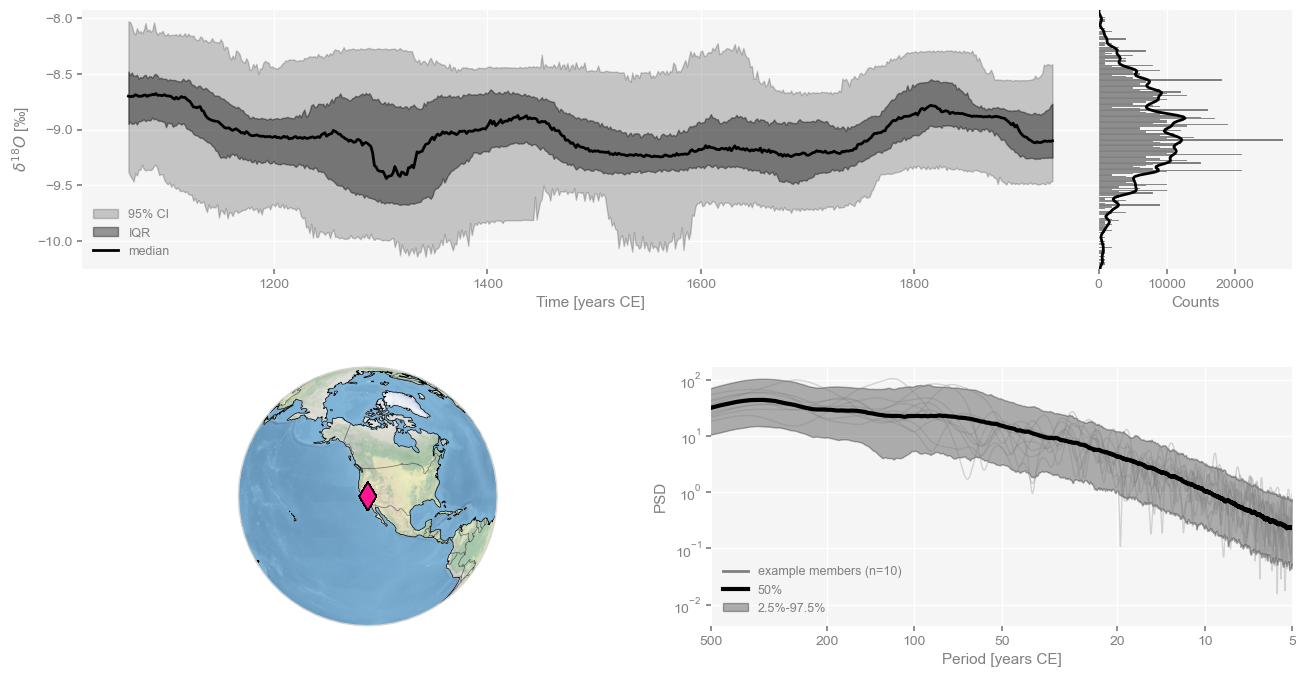

In [49]:
cc_ens.dashboard()

Ahora, lo que nos gustaría hacer es repetir el ejercicio de la Parte 1, correlacionando la misma serie temporal de TSM de 32.5N 142.5W (cerca de la Extensión de Kuroshio), no solo con la cronología publicada, sino con todo este conjunto. Recordemos cómo habíamos calculado las cosas:

In [50]:
corr_res = stts.correlation(cc, seed = 22)
print(corr_res)

Evaluating association on surrogate pairs: 100%|█| 1000/1000 [00:00<00:00, 1262.

  correlation    p-value  signif. (α: 0.05)
-------------  ---------  -------------------
     0.323596       0.12  False



Aunque, por supuesto, podríamos haber hecho justo lo contrario, ya que la correlación es un operador simétrico:

In [51]:
corr_res = cc.correlation(stts, seed = 22)
print(corr_res)

Evaluating association on surrogate pairs: 100%|█| 1000/1000 [00:00<00:00, 1267.

  correlation    p-value  signif. (α: 0.05)
-------------  ---------  -------------------
     0.323596       0.12  False



Ahora, considere la tarea que tenemos por delante: un usuario debe iterar sobre todos los miembros del conjunto, cuidando de alinear su eje temporal con el de HadSST4; debe calcular la correlación y establecer su significancia con una prueba sensata (Trampa #1), cuidando la multiplicidad de pruebas (ver Trampa #2) y visualizando los resultados de una manera intuitiva. pyleoclim simplifica este proceso, el cual ilustraremos aquí para la ubicación de la Extensión de Kuroshio, tal como se hizo anteriormente. Para mantener el tiempo de computación manejable, reducimos el número de simulaciones isoespectrales a 100, y correlacionamos el conjunto y la serie de TSM con la que comenzamos:

In [52]:
corr_Kuroshio = cc_ens.correlation(stts,number = 100,seed = 453) 

Looping over 1000 Series in the ensemble


  0%|                                          | 1/1000 [00:00<02:55,  5.71it/s]

Time axis values sorted in ascending order


100%|███████████████████████████████████████| 1000/1000 [01:55<00:00,  8.66it/s]


De nuevo, corr_Kuroshio es un objeto CorrEns, que contiene todo lo que desea: el vector de correlaciones, los valores p y un método para graficarlos todos:

(<Figure size 400x400 with 1 Axes>, <Axes: xlabel='$r$', ylabel='Count'>)

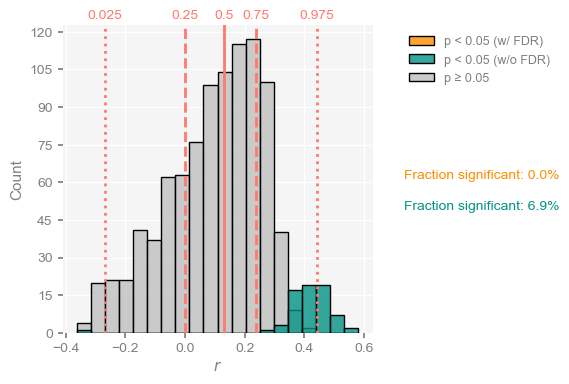

In [53]:
corr_Kuroshio.plot()

Varias cosas saltan a la vista de inmediato:
1. El histograma de correlaciones es relativamente simétrico, lo que significa que las incertidumbres de edad son capaces de anular por completo la correlación original de aproximadamente 0,32 (casi la mitad del conjunto presenta correlaciones negativas con la TSM).  
1. Como se muestra en color verde azulado (teal), solo alrededor del 4% de las 500*100 correlaciones recién calculadas se juzgan significativas. 
1. Una vez que tenemos en cuenta la multiplicidad de pruebas mediante la Tasa de Falsos Descubrimientos (barra naranja), solo una fracción de un % se considera significativa. 

Para guardar la figura:

In [54]:
corr_Kuroshio.plot(savefig_settings={'path':'CrystalCave_ageens_corr_hist.pdf'})

Figure saved at: "CrystalCave_ageens_corr_hist.pdf"


(<Figure size 400x400 with 1 Axes>, <Axes: xlabel='$r$', ylabel='Count'>)

## Conclusion

Vemos, al igual que en Hu et al (2017), que todas estas trampas importan. Cualquiera de ellas por sí sola puede convertir una correlación inicialmente reportada como significativa en una no significativa, y el panorama empeora si estas trampas se combinan entre sí. La conjunción de las tres trampas (persistencia, multiplicidad de pruebas e incertidumbres de edad) es particularmente dañina en este ejemplo, invalidando la interpretación publicada del $\delta^{18}O$ de Crystal Cave como un proxy de la TSM de la Extensión de Kuroshio. Pyleoclim facilita el manejo de esas trampas, lo cual esperamos ayude a evitar correlaciones espurias en paleoclimatología y paleoceanografía. Cabe enfatizar, como lo hicieron Hu et al (2017), que una correlación lineal significativa no es ni una condición necesaria ni suficiente para establecer la interpretación de una serie proxy, y que generalmente se necesitan modelos mecanicistas o monitoreo in situ.

## References

- Benjamini, Y., and Y. Hochberg (1995), Controlling the false discovery rate: A practical and powerful approach to multiple testing, Journal of the Royal Statistical Society. Series B (Methodological), 57(1), 289–300, doi:10.2307/2346101.

- Dawdy, D., and N. Matalas (1964), Statistical and probability analysis of hydro- logic data, part III: Analysis of variance, covariance and time series, McGraw-Hill.

- Ebisuzaki, W. (1997), A method to estimate the statistical significance of a correlation when the data are serially correlated, Journal of Climate, 10(9), 2147–2153, doi:10.1175/1520- 0442(1997)010¡2147:AMTETS¿2.0.CO;2

- Gelman, A., and H. Stern (2006), The difference between “significant” and “not significant” is not itself statistically significant, The American Statistician, 60(4), 328–331, doi: 10.1198/000313006X152649.

- Haslett, J., and A. Parnell (2008), A simple monotone process with application to radiocarbon-dated depth chronologies, Journal of the Royal Statistical Society: Series C (Applied Statistics), 57(4), 399–418, doi:10.1111/j.1467-9876.2008.00623.x.

- Hu, J., J. Emile-Geay, and J. Partin (2017), Correlation-based interpretations of paleoclimate data – where statistics meet past climates, Earth and Planetary Science Letters, 459, 362–371, doi:10.1016/j.epsl.2016.11.048

- McCabe-Glynn, S., K. R. Johnson, C. Strong, M. Berkelhammer, A. Sinha, H. Cheng, and R. L. Edwards (2013), Variable North Pacific influence on drought in southwestern North America since AD 854, Nat. Geosci., 6(8), 617–621, doi:10.1038/NGEO1862.

- Morice, C. P., J. J. Kennedy, N. A. Rayner, and P. D. Jones (2012), Quantifying uncertainties in global and regional temperature change using an ensemble of observational estimates: The HadCRUT4 data set, Journal of Geophysical Research: Atmospheres, 117(D8), n/a–n/a, doi:10.1029/2011JD017187.

- Rehfeld, K., and J. Kurths (2014), Similarity estimators for irregular and age-uncertain time series, Climate of the Past, 10(1), 107–122, doi:10.5194/cp-10-107-2014

- Wilks, D. S. (2011), Statistical Methods in the Atmospheric Sciences: an Introduction, 676 pp., Academic Press, San Diego
